# Module 5 - Big Data Analytics
**What this module covers:** why big-data tools are needed for this dataset, the document vs relational data model,
**MongoDB accident storage** (GeoJSON + 2dsphere index, 10 queries/aggregations timed with and without indexes),
the **Hadoop data flow** with MapReduce (Hadoop Streaming mapper/reducer for three jobs, run locally with the exact
map -> sort -> reduce flow), a three-way cross-check (pandas vs MongoDB vs MapReduce), the optional PySpark code
and the end-to-end data-flow diagram.

**Project tasks satisfied here:** *Big Data: MongoDB accident storage; Hadoop data flow (MapReduce).*

Code: `bigdata/mongodb/`, `bigdata/hadoop_mapreduce/`, `bigdata/spark_optional/` (not executed).

In [1]:
import sys, json, subprocess, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "bigdata" / "mongodb"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
from src import utils as U, viz as V
import load_to_mongo, queries

V.apply_style()
MET, FIG = U.METRICS, U.FIGURES
stats_ = U.load_json(MET / "dataset_stats.json")
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| interpreter:", Path(sys.executable).parent.parent.name)

Python 3.14.2 | pandas 3.1.0 | interpreter: .venv


## 1. Why big-data tools?
The three "V"s, measured on this dataset:

In [2]:
raw_gb = U.DATA_RAW.stat().st_size / 1e9
pq_mb = U.CLEAN_PARQUET.stat().st_size / 1e6
blocks = int(np.ceil(U.DATA_RAW.stat().st_size / (128 * 1024 ** 2)))
vt = pd.DataFrame([
    ("Volume", f"{stats_['total_rows']:,} rows x {stats_['total_columns']} columns, {raw_gb:.2f} GB CSV"),
    ("Volume (HDFS view)", f"{blocks} blocks of 128 MB; x3 replication = {3 * blocks} block replicas"),
    ("Velocity", f"records from {stats_['date_min'][:10]} to {stats_['date_max'][:10]}, streamed from traffic APIs"),
    ("Variety", "numeric weather, timestamps, GPS points, categorical text, booleans, free-text descriptions"),
    ("Laptop strategy", f"chunked reads of {stats_['chunksize']:,} rows; columnar Parquet sample = {pq_mb:.1f} MB"),
], columns=["aspect", "this project"])
vt

,aspect,this project
0,Volume,"7,728,394 rows x 46 columns, 3.06 GB CSV"
1,Volume (HDFS view),23 blocks of 128 MB; x3 replication = 69 block...
2,Velocity,"records from 2016-01-14 to 2023-03-31, streame..."
3,Variety,"numeric weather, timestamps, GPS points, categ..."
4,Laptop strategy,"chunked reads of 500,000 rows; columnar Parque..."


Loading the whole CSV into pandas needs several times its size in RAM, so Module 1 streamed it in chunks - the
same *split -> process -> combine* idea that MapReduce and Spark use across machines.

## 2. Document model vs relational model
| | Relational (SQL) | Document (MongoDB) |
|---|---|---|
| Unit | row in a fixed-schema table | JSON/BSON document, flexible fields |
| Missing values | NULL in every row | field simply absent (sparse weather data stores well) |
| Geo data | extension needed (PostGIS) | native GeoJSON + `2dsphere` index, `$geoNear` |
| Joins | normalised tables + joins | related data embedded in one document (accident + weather + road flags) |
| Scale-out | mostly vertical | horizontal sharding, replica sets |
| Best for | transactions, strict integrity | read-heavy analytics on semi-structured events |

An accident is a self-contained event that is written once and read many times, with many optional fields, so a
document store fits it naturally.

## 3. MongoDB - load `traffic_db.accidents`

In [3]:
load_info = load_to_mongo.main()
coll = load_to_mongo.get_client()[load_to_mongo.DB][load_to_mongo.COLL]
idx = pd.DataFrame([{"index": k, "keys": str(v["key"])} for k, v in coll.index_information().items()])
display(idx)
doc = coll.find_one({}, {"_id": 1, "Severity": 1, "Start_Time": 1, "City": 1, "State": 1, "WeatherGroup": 1,
                         "Temperature_F": 1, "location": 1, "Junction": 1})
print(json.dumps(doc, default=str, indent=2))

{'database': 'traffic_db', 'collection': 'accidents', 'documents': 399581, 'batch_size': 10000, 'batches': 40, 'load_seconds': 6.2, 'indexes': ['location_2dsphere', 'State_1', 'Severity_1', 'Start_Time_1'], 'storage_size_mb': 41.0, 'avg_doc_bytes': 679, 'server_version': '9.0.4'}


,index,keys
0,_id_,"[('_id', 1)]"
1,location_2dsphere,"[('location', '2dsphere')]"
2,State_1,"[('State', 1)]"
3,Severity_1,"[('Severity', 1)]"
4,Start_Time_1,"[('Start_Time', 1)]"


{
  "_id": "A-337795",
  "Severity": 1,
  "Start_Time": "2017-02-22 11:52:04",
  "City": "San Jose",
  "State": "CA",
  "Temperature_F": 55.0,
  "WeatherGroup": "Cloudy",
  "Junction": false,
  "location": {
    "type": "Point",
    "coordinates": [
      -121.904472,
      37.346977
    ]
  }
}


## 4. MongoDB queries and aggregations - timed with and without indexes
Each query runs once to warm up, then 5 times; the median is reported. Then the secondary and 2dsphere indexes are
dropped, the queries are re-run, and the indexes are restored. `plan` is the winning stage from `explain()`.

In [4]:
mres = queries.main()
mres["load"] = load_info
U.save_json(mres, MET / "mongo_results.json")
qt = pd.DataFrame([{k: q[k] for k in ["name", "description", "ms_with_index", "plan_with_index", "ms_without_index", "plan_without_index"]}
                   for q in mres["queries"]])
qt["speedup"] = (qt["ms_without_index"] / qt["ms_with_index"]).round(1)
qt

count_by_state           with index    199.96 ms (COLLSCAN         )  without 175.54 ms


avg_severity_by_weather  with index    287.13 ms (COLLSCAN         )  without 270.49 ms


top_cities               with index    285.83 ms (COLLSCAN         )  without 271.06 ms


hourly_distribution      with index    213.54 ms (COLLSCAN         )  without 200.8 ms


severity_counts          with index    171.61 ms (COLLSCAN         )  without 157.83 ms
geo_near_hotspot         with index     46.72 ms (GEO_NEAR_2DSPHERE)  without None ms


time_range_jan_2022      with index      2.07 ms (IXSCAN           )  without 176.03 ms


ca_severity_4            with index     12.48 ms (IXSCAN           )  without 199.29 ms


top_states_severe        with index      91.6 ms (IXSCAN           )  without 202.57 ms


latest_ny                with index      0.65 ms (IXSCAN           )  without 216.13 ms


,name,description,ms_with_index,plan_with_index,ms_without_index,plan_without_index,speedup
0,count_by_state,Accidents per state ($group + $sort),199.96,COLLSCAN,175.54,COLLSCAN,0.9
1,avg_severity_by_weather,Average severity and count per weather group,287.13,COLLSCAN,270.49,COLLSCAN,0.9
2,top_cities,"Top 10 cities ($group on City+State, $sort, $l...",285.83,COLLSCAN,271.06,COLLSCAN,0.9
3,hourly_distribution,Accidents per hour of day,213.54,COLLSCAN,200.80,COLLSCAN,0.9
4,severity_counts,Accidents per severity level,171.61,COLLSCAN,157.83,COLLSCAN,0.9
5,geo_near_hotspot,$geoNear: accidents within 10 km of the top ho...,46.72,GEO_NEAR_2DSPHERE,NaN,not possible: $geoNear requires the location_2...,NaN
6,time_range_jan_2022,Accidents with Start_Time in January 2022 (ran...,2.07,IXSCAN,176.03,COLLSCAN,85.0
7,ca_severity_4,Severity-4 accidents in California (equality f...,12.48,IXSCAN,199.29,COLLSCAN,16.0
8,top_states_severe,Top 5 states by severe (3-4) accidents ($match...,91.60,IXSCAN,202.57,COLLSCAN,2.2
9,latest_ny,5 most recent accidents in NY (find + sort + l...,0.65,IXSCAN,216.13,COLLSCAN,332.5


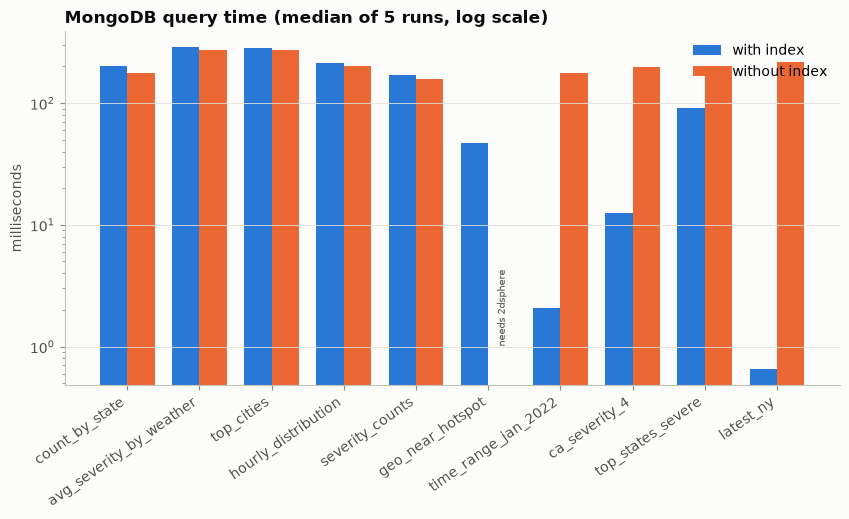

,Severity,accidents,avg_dist_km
0,1,4,7.907118
1,2,4138,5.669471
2,3,1052,5.486786
3,4,32,5.156360


In [5]:
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(qt)); w = 0.38
ax.bar(x - w / 2, qt["ms_with_index"], w, color=V.PRIMARY, label="with index")
ax.bar(x + w / 2, qt["ms_without_index"].fillna(0), w, color=V.ACCENT, label="without index")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(qt["name"], rotation=35, ha="right")
ax.set(title="MongoDB query time (median of 5 runs, log scale)", ylabel="milliseconds"); ax.legend()
ax.annotate("needs 2dsphere", (x[qt.name == "geo_near_hotspot"][0] + w / 2, 1), ha="center", fontsize=7, color=V.INK2, rotation=90, va="bottom")
V.save(fig, FIG / "mongo_query_timings.png")
geo = next(q for q in mres["queries"] if q["name"] == "geo_near_hotspot")
pd.DataFrame(geo["result"]).rename(columns={"_id": "Severity"})

**Reading the timings:** filters on an indexed field (`time_range_jan_2022`, `ca_severity_4`, `latest_ny`,
`top_states_severe`) switch from a full collection scan (COLLSCAN) to an index scan (IXSCAN). Whole-collection
`$group` aggregations must read every document either way, so an index does not help them. `$geoNear` cannot run
without the 2dsphere index.

## 5. Hadoop data flow - HDFS + MapReduce
**HDFS** stores a large file as fixed-size blocks (128 MB by default) replicated on several DataNodes; the NameNode
keeps the block map. **MapReduce** ships the code to the data: one *map task* per input split emits `key \t value`
pairs, the framework *partitions* them by key across reducers, *sorts* each partition (shuffle & sort) and every
*reduce task* aggregates the values of each key. Hadoop Streaming lets the mapper and reducer be any program that
reads stdin and writes stdout - here `mapper.py` and `reducer.py`.

`run_pipeline.py` reproduces these stages locally with the unchanged scripts: 4 input splits -> 4 map tasks ->
partition `zlib.crc32(key) % 2` -> sort -> 2 reduce tasks -> merged output, and records the real counters. The
optional real-cluster setup (`docker-compose.yml`, `hdfs dfs -put`, `hadoop jar hadoop-streaming.jar ...`) is in
`bigdata/hadoop_mapreduce/README.md` and **was not executed** (Docker is not installed on this laptop).

In [6]:
sys.path.insert(0, str(ROOT / "bigdata" / "hadoop_mapreduce"))
import run_pipeline
(ROOT / "bigdata" / "hadoop_mapreduce" / "input" / "accidents.tsv").unlink(missing_ok=True)   # rebuild input from the parquet
counters = run_pipeline.main()
skip = ("map_input_records_per_split", "partition_records", "user_counters", "output")
ct = pd.DataFrame({job: {k: v for k, v in c.items() if k not in skip} for job, c in counters["jobs"].items()}).T
ct["records_per_partition"] = [str(c["partition_records"]) for c in counters["jobs"].values()]
ct

job=state    map_in=399,581 map_out=399,581 partitions=[137449, 262132] groups=49 out=49 0.72 s


job=weather  map_in=399,581 map_out=399,581 partitions=[359270, 40311] groups=7 out=7 0.74 s


job=hour     map_in=399,581 map_out=399,581 partitions=[215650, 183931] groups=24 out=24 0.88 s


,splits,map_tasks,map_input_records,map_output_records,partitions,reduce_tasks,reduce_input_groups,reduce_output_records,seconds,records_per_partition
state,4.0,4.0,399581.0,399581.0,2.0,2.0,49.0,49.0,0.72,"[137449, 262132]"
weather,4.0,4.0,399581.0,399581.0,2.0,2.0,7.0,7.0,0.74,"[359270, 40311]"
hour,4.0,4.0,399581.0,399581.0,2.0,2.0,24.0,24.0,0.88,"[215650, 183931]"


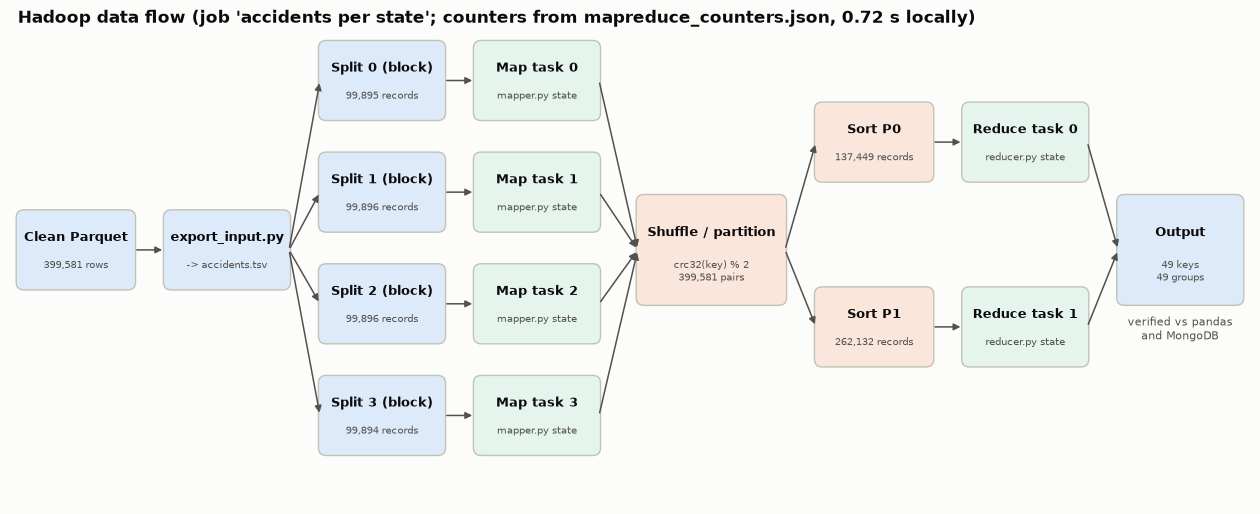

In [7]:
c = counters["jobs"]["state"]
fig, ax = plt.subplots(figsize=(16, 6.4)); ax.set_xlim(0, 16); ax.set_ylim(0, 6.4); ax.axis("off")
def box(x, y, w, h, title, sub, color, fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.1", fc=color, ec=V.AXIS, lw=1))
    ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=fs, fontweight="bold", color=V.INK)
    ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=7.5, color=V.INK2)
def arrow(x0, y0, x1, y1):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color=V.INK2, lw=1.1))
L, G, O = "#dceaf9", "#e6f4ee", "#fbe6dc"
box(0.1, 2.8, 1.5, 1.0, "Clean Parquet", f"{c['map_input_records']:,} rows", L)
box(2.0, 2.8, 1.6, 1.0, "export_input.py", "-> accidents.tsv", L)
arrow(1.6, 3.3, 2.0, 3.3)
for i, n in enumerate(c["map_input_records_per_split"]):
    y = 5.0 - i * 1.45
    box(4.0, y, 1.6, 1.0, f"Split {i} (block)", f"{n:,} records", L)
    box(6.0, y, 1.6, 1.0, f"Map task {i}", "mapper.py state", G)
    arrow(3.6, 3.3, 4.0, y + 0.5); arrow(5.6, y + 0.5, 6.0, y + 0.5); arrow(7.6, y + 0.5, 8.1, 3.3)
box(8.1, 2.6, 1.9, 1.4, "Shuffle / partition", "crc32(key) % 2" + chr(10) + f"{c['map_output_records']:,} pairs", O)
for j, n in enumerate(c["partition_records"]):
    y = 4.2 - j * 2.4
    box(10.4, y, 1.5, 1.0, f"Sort P{j}", f"{n:,} records", O)
    box(12.3, y, 1.6, 1.0, f"Reduce task {j}", "reducer.py state", G)
    arrow(10.0, 3.3, 10.4, y + 0.5); arrow(11.9, y + 0.5, 12.3, y + 0.5); arrow(13.9, y + 0.5, 14.3, 3.3)
box(14.3, 2.6, 1.6, 1.4, "Output", f"{c['reduce_output_records']} keys" + chr(10) + f"{c['reduce_input_groups']} groups", L)
ax.text(15.1, 2.45, "verified vs pandas" + chr(10) + "and MongoDB", ha="center", va="top", fontsize=8, color=V.INK2)
ax.text(0.1, 6.25, f"Hadoop data flow (job 'accidents per state'; counters from mapreduce_counters.json, {c['seconds']} s locally)",
        fontsize=12, fontweight="bold", color=V.INK)
V.save(fig, FIG / "hadoop_data_flow.png")

## 6. Three-way cross-check: MapReduce vs pandas vs MongoDB
All three engines read the same cleaned rows, so counts must be equal and averages must agree to 1e-6.

In [8]:
from src.bigdata_check import crosscheck
xres, xdetail = crosscheck()
pd.DataFrame(xres["jobs"]).T

,title,keys_pandas,keys_mapreduce,keys_mongodb,mismatches,status
state,accidents per state,49,49,49,0,PASS
weather,average severity per weather group,7,7,7,0,PASS
hour,accidents per hour,24,24,24,0,PASS


In [9]:
xdetail[xdetail.job == "average severity per weather group"]

,job,key,pandas,mapreduce,mongodb,match
49,average severity per weather group,Clear,2.187721,2.187721,2.187721,True
50,average severity per weather group,Cloudy,2.235008,2.235008,2.235008,True
51,average severity per weather group,Fog/Haze,2.175080,2.175080,2.175080,True
52,average severity per weather group,Other,2.097561,2.097561,2.097561,True
53,average severity per weather group,Rain,2.249121,2.249121,2.249121,True
54,average severity per weather group,Snow,2.240933,2.240933,2.240933,True
55,average severity per weather group,Storm,2.220697,2.220697,2.220697,True


In [10]:
xdetail[xdetail.job == "accidents per state"].sort_values("pandas", ascending=False).head(8)

,job,key,pandas,mapreduce,mongodb,match
3,accidents per state,CA,89890.0,89890.0,89890.0,True
8,accidents per state,FL,45340.0,45340.0,45340.0,True
41,accidents per state,TX,30284.0,30284.0,30284.0,True
38,accidents per state,SC,19602.0,19602.0,19602.0,True
32,accidents per state,NY,18112.0,18112.0,18112.0,True
25,accidents per state,NC,17477.0,17477.0,17477.0,True
43,accidents per state,VA,15631.0,15631.0,15631.0,True
36,accidents per state,PA,15178.0,15178.0,15178.0,True


## 7. Optional PySpark version
`bigdata/spark_optional/` holds the original PySpark jobs adapted to local paths. **Not executed**: PySpark does not
support Python 3.14. Spark would run the same group-bys as distributed DataFrame operations with in-memory caching.

## 8. Overall project data flow

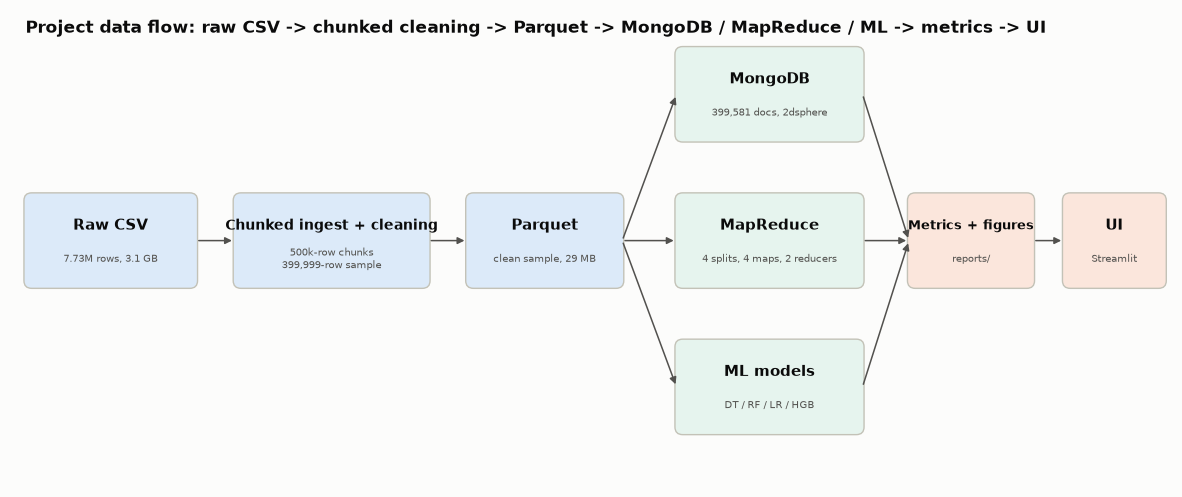

In [11]:
fig, ax = plt.subplots(figsize=(15, 6.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 6.2); ax.axis("off")
box(0.2, 2.6, 2.2, 1.2, "Raw CSV", f"{stats_['total_rows'] / 1e6:.2f}M rows, {raw_gb:.1f} GB", L, 10.5)
box(2.9, 2.6, 2.5, 1.2, "Chunked ingest + cleaning", "500k-row chunks" + chr(10) + f"{stats_['sample_rows']:,}-row sample", L, 10)
box(5.9, 2.6, 2.0, 1.2, "Parquet", f"clean sample, {pq_mb:.0f} MB", L, 10.5)
box(8.6, 4.5, 2.4, 1.2, "MongoDB", f"{load_info['documents']:,} docs, 2dsphere", G, 10.5)
box(8.6, 2.6, 2.4, 1.2, "MapReduce", "4 splits, 4 maps, 2 reducers", G, 10.5)
box(8.6, 0.7, 2.4, 1.2, "ML models", "DT / RF / LR / HGB", G, 10.5)
box(11.6, 2.6, 1.6, 1.2, "Metrics + figures", "reports/", O, 9)
box(13.6, 2.6, 1.3, 1.2, "UI", "Streamlit", O, 10.5)
arrow(2.4, 3.2, 2.9, 3.2); arrow(5.4, 3.2, 5.9, 3.2)
for yy in (5.1, 3.2, 1.3):
    arrow(7.9, 3.2, 8.6, yy); arrow(11.0, yy, 11.6, 3.2)
arrow(13.2, 3.2, 13.6, 3.2)
ax.text(0.2, 5.9, "Project data flow: raw CSV -> chunked cleaning -> Parquet -> MongoDB / MapReduce / ML -> metrics -> UI",
        fontsize=12, fontweight="bold", color=V.INK)
V.save(fig, FIG / "data_flow.png")

## Module 5 summary
MongoDB stores every cleaned accident as a GeoJSON document; indexes turn selective filters from full scans into
index scans and `$geoNear` answers radius questions around hotspots. The local Hadoop data flow reproduces the
pandas aggregations exactly, and so do the MongoDB aggregations (`reports/metrics/bigdata_crosscheck.json`).
The real Hadoop cluster and Spark runs are documented as optional and were not executed.